# 8. K-Nearest Neighbors (KNN) Classification

## Lý thuyết & Nguyên lý

### 8.1. Cơ chế bỏ phiếu đa số (Majority Voting)

KNN Classifier "ghi nhớ" toàn bộ dữ liệu huấn luyện. Với điểm mới $x^*$, tìm $k$ điểm láng giềng gần nhất theo khoảng cách (mặc định Euclidean), rồi **bỏ phiếu** để chọn lớp có nhiều phiếu nhất:

$$\hat{y}(x^*) = \arg\max_{c} \; \sum_{i \in \mathcal{N}_k(x^*)} \mathbb{1}\big[y_i = c\big]$$

Trong đó $\mathcal{N}_k(x^*)$ là tập $k$ chỉ số gần nhất, $\mathbb{1}[\cdot]$ là hàm chỉ báo (indicator function).

**Bỏ phiếu có trọng số (weighted voting):** mỗi phiếu được nhân với trọng số nghịch đảo khoảng cách — điểm gần hơn "nặng" hơn:

$$\hat{y}(x^*) = \arg\max_{c} \; \sum_{i \in \mathcal{N}_k(x^*)} \frac{\mathbb{1}[y_i = c]}{d(x^*, x_i)}$$

Tính chất thú vị: khi $k=1$ và weights='distance', mô hình sinh ranh giới là **Voronoi diagram** — các vùng quanh từng điểm huấn luyện.

### 8.2. Vai trò của $k$ — đánh đổi Bias–Variance

- **$k$ nhỏ ($k=1,3$):** ranh giới quyết định **rắc, chi tiết**, bám sát từng điểm → phương sai cao, **overfitting**; nhạy với điểm nhiễu/outlier.
- **$k$ lớn:** ranh giới **mịn, tròn** → bias cao, **underfitting**; mất các chi tiết quan trọng của dữ liệu.
- Trong phân loại chọn **$k$ lẻ** (với 2 lớp) để tránh hòa phiếu.

### 8.3. Hai lưu ý thiết yếu (giống KNN Regression)

1. **Chuẩn hóa bắt buộc** — khoảng cách Euclidean chịu ảnh hưởng trực tiếp của thang đo đặc trưng.
2. **Curse of dimensionality** — ở chiều cao, mọi điểm đều cách nhau gần bằng nhau, khái niệm "láng giềng" mất ý nghĩa → KNN yếu khi $p$ lớn hoặc dữ liệu thưa.


Accuracy trên toàn bộ dữ liệu huấn luyện: 1.0000


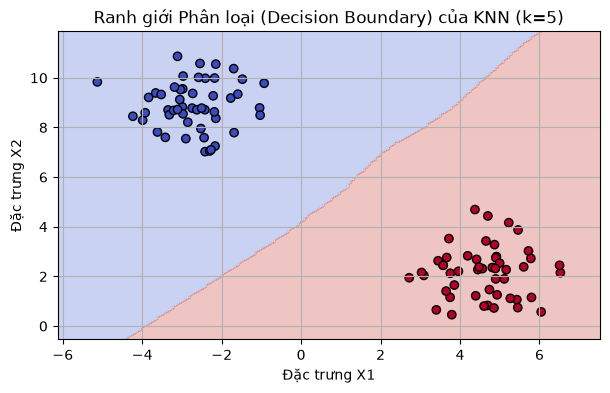

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier

# 1. Tạo dữ liệu 2 cụm, 2 lớp
X, y = make_blobs(n_samples=100, centers=2, random_state=42)

# 2. Huấn luyện KNN Classifier k = 5
knn = KNeighborsClassifier(n_neighbors=5).fit(X, y)

# 3. Tạo lưới tọa độ vẽ Ranh giới Quyết định (Decision Boundary)
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200),
    np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200),
)
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7, 4))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k')
plt.title('Ranh giới Phân loại (Decision Boundary) của KNN (k=5)')
plt.xlabel('Đặc trưng X1')
plt.ylabel('Đặc trưng X2')
plt.grid(True)
plt.show()

print(f"Accuracy trên toàn bộ dữ liệu huấn luyện: {knn.score(X, y):.4f}")


## Ý nghĩa của biểu đồ

- Hai vùng màu (xanh/đỏ) được tạo bởi việc "sơn màu" cho từng ô lưới theo phiếu bầu của 5 láng giềng gần nhất → ranh giới **hơi lởm chởm, không tròn trịa** (đặc trưng KNN với $k$ nhỏ và dữ liệu thưa).
- Với dữ liệu 2 cụm tách rời rõ ràng, KNN phân tách gần đúng — ranh giới thực sự nằm giữa hai cụm.

---

## Tổng quan mô hình

### Ưu điểm

- **Phi tham số, không huấn luyện** — đơn giản, trực quan, dễ giải thích ("phân loại theo 5 điểm tương tự gần nhất").
- **Bắt được ranh giới phức tạp, phi tuyến** nếu dữ liệu đủ dày và đều.
- **Ít giả định** — không cần dữ liệu tuyến tính, phân phối chuẩn...
- **Dễ cập nhật:** thêm dữ liệu mới chỉ cần đưa vào tập huấn luyện (không cần huấn luyện lại) — miễn là còn nhớ được dữ liệu.

### Nhược điểm

- **Chậm dự đoán:** mỗi truy vấn tính khoảng cách với toàn bộ $n$ mẫu — tốn kém với dữ liệu lớn (có thể giảm bằng KD-Tree/Ball Tree/ANN).
- **Phải chuẩn hóa** đặc trưng, không thì mô hình sai lệch.
- **Yếu ở chiều cao** (curse of dimensionality) và với dữ liệu lệch lớp/mật độ không đều.
- **Không extrapolate:** ngoài miền dữ liệu huấn luyện, quyết định bị chi phối bởi các điểm rìa.
- Nhạy với outlier: một điểm lạ lọt vào có thể đảo chiều bỏ phiếu ở $k$ nhỏ.

### Siêu tham số quan trọng

| Tham số | Vai trò | Gợi ý |
| :--- | :--- | :--- |
| `n_neighbors` | Số láng giềng $k$ | Lẻ; bắt đầu từ $\sqrt{n}$; quét qua GridSearchCV |
| `weights` | 'uniform' hay 'distance' | Lệch mật độ → 'distance' |
| `metric` | Euclidean / Manhattan / Minkowski | Đa số: 'minkowski' với $p=2$ |
| `p` | Tham số Minkowski | 1 = Manhattan, 2 = Euclidean |
| `algorithm` | auto / ball_tree / kd_tree / brute | Tự động; KD-Tree tốt cho $p$ nhỏ |

### Các trường hợp sử dụng thực tế

| Lĩnh vực | Ứng dụng cụ thể | Đặc trưng đầu vào ($X$) | Lớp ($Y$) |
| :--- | :--- | :--- | :--- |
| **Y tế** | Phân loại ca bệnh dự trên hồ sơ tương tự | Tuổi, huyết áp, chỉ số xét nghiệm | Bình thường / Bệnh |
| **Tài chính** | Phát hiện giao dịch bất thường | Số tiền, thời gian, địa điểm, tần suất | Bình thường / Bất thường |
| **Nhận dạng** | Phân loại chữ viết tay / khuôn mặt đặc trưng | vector đặc trưng ảnh (PCA/HOG) | Nhãn lớp |
| **Nông nghiệp** | Phân loại chất lượng nông sản | Màu sắc, trọng lượng, kích thước, độ ẩm | Hàng A / Hàng B |
| **Bán lẻ** | Gợi ý sản phẩm cho người dùng mới | vector hành vi mua sắm | Phân khúc khách hàng |

### Mẹo thực hành

- **Bọc scaler vào Pipeline** để tránh rò rỉ dữ liệu test khi chuẩn hóa.
- Với dữ liệu nhiều chiều, giảm chiều trước (PCA) rồi mới áp KNN.
- Nếu dữ liệu rất lớn, thay KNN bằng **Approximate Nearest Neighbors** (ví dụ FAISS, hnswlib) hoặc dùng mô hình tuyến tính hóa nhanh như baseline.


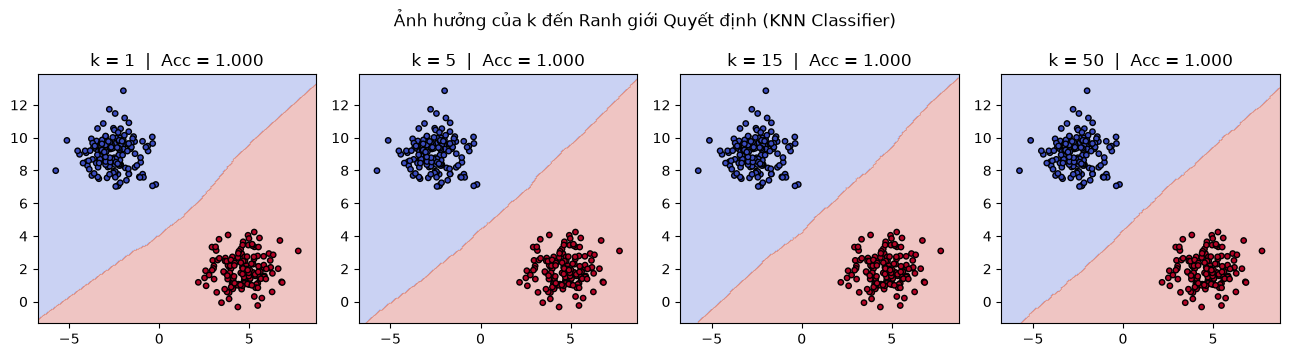

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

# 1. Dữ liệu 2 lớp, nhiều mẫu hơn để thấy rõ vai trò của k
np.random.seed(42)
X, y = make_blobs(n_samples=300, centers=2, random_state=42)

# 2. Vẽ ranh giới quyết định cho nhiều giá trị k
ks = [1, 5, 15, 50]
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200),
    np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200),
)
grid = np.c_[xx.ravel(), yy.ravel()]

plt.figure(figsize=(13, 3.6))
for i, k in enumerate(ks, 1):
    knn = KNeighborsClassifier(n_neighbors=k).fit(X, y)
    acc = accuracy_score(y, knn.predict(X))
    Z = knn.predict(grid).reshape(xx.shape)

    plt.subplot(1, len(ks), i)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=15)
    plt.title(f'k = {k}  |  Acc = {acc:.3f}')

plt.suptitle('Ảnh hưởng của k đến Ranh giới Quyết định (KNN Classifier)')
plt.tight_layout()
plt.show()


## Giải thích kết quả

- **$k=1$:** ranh giới quyết định bám sát từng điểm — chi tiết nhất, nhưng một điểm nhiễu nằm giữa cụm đối phương có thể tạo "đảo" phân loại riêng (overfitting).
- **$k=5, 15$:** ranh giới dần mượt và ổn định hơn, bỏ qua nhiễu nhỏ nhưng vẫn tách đúng hai cụm.
- **$k=50$:** ranh giới gần như thành một **đường thẳng** (quyết định bởi tỷ lệ lớp trong vùng lớn) — mượt nhưng có nguy cơ mất chi tiết (underfitting) với dữ liệu phức tạp hơn.

Thông điệp: chọn $k$ là **nghệ thuật điều chỉnh độ nhạy của ranh giới** — kiểm chứng chéo (cross-validation) là cách duy nhất chọn $k$ đáng tin cậy.
